# YAMNet cough verification filter (segment-based)

Double-checks that CoughVid files actually contain a cough using PyTorch YAMNet (`w-hc/torch_audioset`, AudioSet 521 classes), then filters the dataframe on that score instead of the original `cough_detected`.

The "Cough" class index is looked up from the official `yamnet_class_map.csv` at runtime (index 42 — index 41 is "Snort", an easy off-by-one).

Each wav is segmented into cough regions with `segment_cough_fast` (same segmentation `make_dataset()` uses), segments are zero-padded to 1s and scored by YAMNet. The file's score is the **highest YAMNet cough score found within its generated segments** (max over segment frames).

- GPU/CPU toggle in the config cell.
- Scores cached to `data/yamnet_scores.parquet`; streamed in chunks, flushed every `FLUSH_EVERY` chunks (safe to interrupt and re-run).

In [1]:
# %pip install git+https://github.com/w-hc/torch_audioset

In [2]:
import polars as pl
import numpy as np
import numpy.typing as npt
import soundfile as sf
import torch
import torchaudio.functional as AF
from torch_audioset.yamnet import yamnet
from torch_audioset.data.torch_input_processing import WaveformToInput
from modules.preprocessing.audio_process import segment_cough_fast
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import urllib.request

# ---- config ----
USE_GPU = True   # set False to force CPU; falls back to CPU if no CUDA
DEVICE = torch.device('cuda' if (USE_GPU and torch.cuda.is_available()) else 'cpu')
BATCH_FRAMES = 256       # frames per forward pass (YAMNet frames are 0.96s)
CHUNK_FILES = 512        # files scored per chunk (bounds RAM/GPU memory)
FLUSH_EVERY = 8          # write cache to disk every N chunks
THRESHOLD = 0.3          # cough score threshold
CACHE_PATH = Path('data/yamnet_scores.parquet')
TARGET_SR = 16000
FRAME_SAMPLES = 15360    # 0.96s at 16k — WaveformToInput's window
MIN_SEG_SAMPLES = TARGET_SR   # pad segments to >= 1s so YAMNet gets a full frame

# official class map -> cough index at runtime (never hardcode)
CLASS_MAP_PATH = Path('data/yamnet_class_map.csv')
if not CLASS_MAP_PATH.exists():
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/tensorflow/models/master/research/audioset/yamnet/yamnet_class_map.csv',
        CLASS_MAP_PATH,
    )
class_map = pl.read_csv(CLASS_MAP_PATH)
COUGH_IDX = class_map.filter(pl.col('display_name') == 'Cough')['index'][0]

print(f'device: {DEVICE}, cough class index: {COUGH_IDX}')

device: cuda, cough class index: 42


In [3]:
df = pl.read_csv('data/tabular_form/tabular_form/coughvid_v3.csv', schema_overrides={'age': pl.Float32})

def make_path(audio_name: str) -> str:
    return f'data/public_dataset_v3_wav/{audio_name.split(".")[0]}.wav'

df = df.with_columns(pl.col('audio_name').map_elements(make_path, return_dtype=pl.String).alias('wav_path'))
print(df.shape)
df.head(3)

(34434, 12)


datetime,cough_detected,latitude,longitude,age,gender,respiratory_condition,fever_muscle_pain,status,file_name,audio_name,wav_path
str,f64,f64,f64,f32,str,bool,bool,str,str,str,str
"""2020-04-13T16:30:16.716367+00:…",0.9761,41.8,61.1,17.0,"""female""",true,false,"""healthy""","""0f0762c8-4b9a-4c1e-a6c3-230f9d…","""0f0762c8-4b9a-4c1e-a6c3-230f9d…","""data/public_dataset_v3_wav/0f0…"
"""2020-11-02T07:42:22.878931+00:…",0.0217,null,null,62.0,"""male""",true,false,"""healthy""","""1ed36fa5-19bb-434b-b41f-7fa2b9…","""1ed36fa5-19bb-434b-b41f-7fa2b9…","""data/public_dataset_v3_wav/1ed…"
"""2020-11-18T20:30:54.833009+00:…",0.9886,42.4,3.2,39.0,"""male""",false,false,"""healthy""","""48b283df-8bda-4766-b02e-0efee9…","""48b283df-8bda-4766-b02e-0efee9…","""data/public_dataset_v3_wav/48b…"


In [4]:
model = yamnet(pretrained=True).to(DEVICE).eval()   # ~4MB of weights, not the memory problem
transform = WaveformToInput()

@torch.no_grad()
def frame_cough_scores(frames: torch.Tensor) -> torch.Tensor:
    """frames: [N, 1, 96, 64] on DEVICE -> [N] sigmoid cough probability per frame."""
    out = []
    for i in range(0, len(frames), BATCH_FRAMES):
        scores = model(frames[i:i + BATCH_FRAMES], to_prob=True)   # [B, 521]
        out.append(scores[:, COUGH_IDX])
    return torch.cat(out)

@torch.no_grad()
def frame_top_classes(frames: torch.Tensor, k: int = 5) -> list[tuple[str, float]]:
    """Top-k predicted classes of the best frame — for eyeballing what the model hears."""
    scores = model(frames.to(DEVICE), to_prob=True)               # [N, 521]
    best = scores[scores.max(dim=1).values.argmax()]              # most confident frame
    vals, idxs = best.topk(k)
    names = dict(zip(class_map['index'], class_map['display_name']))
    return [(names[int(i)], float(v)) for v, i in zip(vals, idxs)]

def seg_to_frames(seg: npt.NDArray, sr: int) -> torch.Tensor:
    """One cough segment -> yamnet frames [T, 1, 96, 64]; 16k resample + zero-pad to >= 1s
    (short coughs) and pad the final <0.96s tail that WaveformToInput would drop."""
    s = torch.from_numpy(np.ascontiguousarray(seg))
    if sr != TARGET_SR:
        s = AF.resample(s, sr, TARGET_SR)
    if len(s) < MIN_SEG_SAMPLES:
        s = torch.nn.functional.pad(s, (0, MIN_SEG_SAMPLES - len(s)))
    tail = len(s) % FRAME_SAMPLES
    if tail:
        s = torch.nn.functional.pad(s, (0, FRAME_SAMPLES - tail))
    return transform(s.unsqueeze(0), TARGET_SR)   # [T, 1, 96, 64]

NOSEG = 'noseg'   # sentinel: file readable but segmentation found no cough-like energy

def load_and_frame(wav_path: str):
    """Read wav -> segment coughs -> concatenated yamnet frames [N, 1, 96, 64].
    Returns NOSEG if segmentation found no cough-like energy -> scored 0.0, matching
    production: make_dataset() segments the same way, so such files yield no training
    segments regardless of what YAMNet would say. Returns None if unreadable."""
    try:
        wave, sr = sf.read(wav_path, dtype='float32')
        if wave.ndim > 1:
            wave = wave.mean(axis=1)
    except Exception:
        return None
    segs, _ = segment_cough_fast(wave, sr, cough_padding=0.1, min_cough_len=0.1)
    if not segs:
        return NOSEG
    return torch.cat([seg_to_frames(seg, sr) for seg in segs])

In [6]:
@torch.no_grad()
def score_chunk(paths: list[str]) -> pl.DataFrame:
    """Score one chunk of files; per file = highest segment frame cough score."""
    with ThreadPoolExecutor(max_workers=8) as ex:
        results = list(ex.map(load_and_frame, paths))

    scores = {p: 0.0 for p, r in zip(paths, results) if r is NOSEG}
    frame_lists = [(i, r) for i, r in enumerate(results) if r is not None and r is not NOSEG and len(r)]

    if frame_lists:
        all_frames, file_ids = [], []
        for i, fl in frame_lists:
            all_frames.append(fl)
            file_ids.extend([i] * len(fl))
        big = torch.cat(all_frames).to(DEVICE)      # only this chunk's frames live on GPU
        cough = frame_cough_scores(big)             # [N]
        ids_t = torch.tensor(file_ids, device=DEVICE)
        per_file = torch.full((len(paths),), -1.0, device=DEVICE)
        per_file.scatter_reduce_(0, ids_t, cough, reduce='amax', include_self=True)
        for i, s in enumerate(per_file.cpu()):
            if s >= 0:
                scores[paths[i]] = s.item()
        del big, cough, ids_t, per_file
    rows = [(p, scores.get(p)) for p in paths]
    return pl.DataFrame(rows, schema={'wav_path': pl.String, 'cough_detected_yamnet': pl.Float64}, orient='row')

# cache: only score files not already scored
# NOTE: old caches (panns / snort-index / topk) are incompatible — delete data/yamnet_scores.parquet first.
if CACHE_PATH.exists():
    cached = pl.read_parquet(CACHE_PATH)
    if set(cached.columns) != {'wav_path', 'cough_detected_yamnet'}:
        raise RuntimeError('stale cache schema — delete data/yamnet_scores.parquet and re-run')
else:
    cached = pl.DataFrame(schema={'wav_path': pl.String, 'cough_detected_yamnet': pl.Float64})
done = set(cached['wav_path'])
todo = [p for p in df['wav_path'].to_list() if p not in done]
print(f'{len(done)} cached, {len(todo)} to score')

import time
t0 = time.time()
for n, start in enumerate(range(0, len(todo), CHUNK_FILES)):
    chunk_paths = todo[start:start + CHUNK_FILES]
    cached = pl.concat([cached, score_chunk(chunk_paths)])
    if (n + 1) % FLUSH_EVERY == 0 or start + CHUNK_FILES >= len(todo):
        CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
        cached.write_parquet(CACHE_PATH)
        print(f'  flushed after {min((n + 1) * CHUNK_FILES, len(todo))} files ({time.time() - t0:.0f}s)')
print(f'done in {time.time() - t0:.1f}s')

df = df.join(cached, on='wav_path', how='left')
print(f'files with no score (missing/corrupt): {df["cough_detected_yamnet"].null_count()}')
print(f'files with no cough-like segments (score 0.0): {(df["cough_detected_yamnet"] == 0.0).sum()}')

0 cached, 34434 to score
  flushed after 4096 files (38s)
  flushed after 8192 files (73s)
  flushed after 12288 files (111s)
  flushed after 16384 files (146s)
  flushed after 20480 files (184s)
  flushed after 24576 files (220s)
  flushed after 28672 files (257s)
  flushed after 32768 files (292s)
  flushed after 34434 files (307s)
done in 307.2s
files with no score (missing/corrupt): 0
files with no cough-like segments (score 0.0): 7385


## Sanity: is YAMNet actually detecting coughs?
1. Files the dataset calls strong coughs should score high; files it rejects should score low.
2. For a strong-cough file, print the model's top predicted classes — "Cough" should appear.

In [7]:
hi = df.filter(pl.col('cough_detected') > 0.95)['wav_path'].to_list()[:3]
lo = df.filter(pl.col('cough_detected') < 0.01)['wav_path'].to_list()[:3]
def quick_score(p):
    r = load_and_frame(p)
    if r is None or r is NOSEG or not len(r):
        return 0.0
    return frame_cough_scores(r.to(DEVICE)).max().item()
print('dataset says STRONG cough:')
for p in hi:
    print(f'  {quick_score(p):.3f}  {p}')
print('dataset says NOT a cough:')
for p in lo:
    print(f'  {quick_score(p):.3f}  {p}')

_r = load_and_frame(hi[0])
if _r is not None and _r is not NOSEG and len(_r):
    print('top classes of most confident frame in a strong-cough file:')
    for name, v in frame_top_classes(_r):
        print(f'  {v:.3f}  {name}')

dataset says STRONG cough:
  0.032  data/public_dataset_v3_wav/0f0762c8-4b9a-4c1e-a6c3-230f9d53de47.wav
  0.993  data/public_dataset_v3_wav/48b283df-8bda-4766-b02e-0efee9f7e59c.wav
  0.003  data/public_dataset_v3_wav/8959b753-8b70-4e80-8b00-41b5154ea2f5.wav
dataset says NOT a cough:
  0.000  data/public_dataset_v3_wav/88fcba8b-f750-4fad-9aa8-28d6e778cd84.wav
  0.000  data/public_dataset_v3_wav/9118638e-5f45-4ec5-9030-ee078d92934c.wav
  0.000  data/public_dataset_v3_wav/1b9fe355-7a78-429a-9e75-a1c547506b2d.wav
top classes of most confident frame in a strong-cough file:
  1.000  Silence
  0.000  Speech
  0.000  Music
  0.000  Inside, small room
  0.000  Narration, monologue


## Filter functions
`filter_coughvid_df_yamnet` mirrors `filter_coughvid_df` from `modules/preprocessing/dataframe_process.py`, with the `cough_detected > 0.8` clause replaced by the YAMNet score.

In [24]:
def filter_coughvid_df(df: pl.DataFrame) -> pl.DataFrame:
    """Original filter (cough_detected = dataset's own probability)."""
    return df.filter(
        (pl.col('cough_detected') > 0.8)
        & (pl.col('age').is_not_null())
        & (pl.col('gender').is_not_null())
        & (pl.col('status').is_not_null())
    )

def filter_coughvid_df_yamnet(df: pl.DataFrame, threshold: float = THRESHOLD) -> pl.DataFrame:
    """Same df/columns, but cough_detected is replaced by the yamnet score before filtering."""
    return df.with_columns(pl.col('cough_detected_yamnet').alias('cough_detected')).filter(
        (pl.col('cough_detected') > threshold)
        & (pl.col('age').is_not_null())
        & (pl.col('gender').is_not_null())
        & (pl.col('status').is_not_null())
    )

df_orig = filter_coughvid_df(df)
df_yam = filter_coughvid_df_yamnet(df)
print(f'original filter: {len(df_orig)} rows')
print(f'yamnet filter  : {len(df_yam)} rows')

original filter: 12885 rows
yamnet filter  : 12853 rows


In [20]:
# threshold sweep
base = df.filter(
    pl.col('age').is_not_null() & pl.col('gender').is_not_null() & pl.col('status').is_not_null()
)
for t in [0.1, 0.2, 0.3, 0.5, 0.7]:
    kept = base.filter(pl.col('cough_detected_yamnet') > t)
    agree = kept.filter(pl.col('cough_detected') > 0.8)
    print(f'threshold {t}: keeps {len(kept):6d} | also-pass-original {len(agree):6d} | new-only {len(kept) - len(agree):5d}')

threshold 0.1: keeps  14108 | also-pass-original  10862 | new-only  3246
threshold 0.2: keeps  13415 | also-pass-original  10382 | new-only  3033
threshold 0.3: keeps  12853 | also-pass-original  10013 | new-only  2840
threshold 0.5: keeps  11866 | also-pass-original   9336 | new-only  2530
threshold 0.7: keeps  10547 | also-pass-original   8392 | new-only  2155


In [29]:
THRESHOLD = 0.3

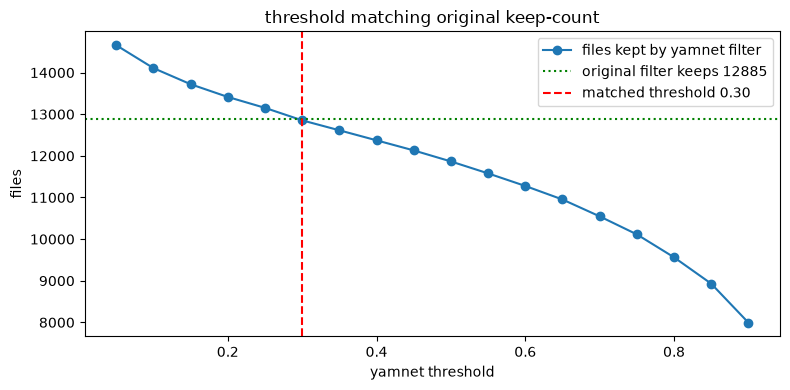

original filter keeps 12885 files -> matching yamnet threshold: 0.30
(at 0.30 yamnet keeps 12853 files)


In [ ]:
# no knee exists (max-score distribution is smooth) — instead pick the threshold that
# keeps the same number of files as the original filter, so the comparison is apples-to-apples
import matplotlib.pyplot as plt

ts = np.arange(0.05, 0.95, 0.05)
kept_n = [len(base.filter(pl.col('cough_detected_yamnet') > t)) for t in ts]
orig_n = len(base.filter(pl.col('cough_detected') > 0.8))

# threshold whose kept-count is closest to the original filter's
best_t = float(ts[np.argmin(np.abs(np.array(kept_n) - orig_n))])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ts, kept_n, 'o-', label='files kept by yamnet filter')
ax.axhline(orig_n, color='g', ls=':', label=f'original filter keeps {orig_n}')
ax.axvline(best_t, color='r', ls='--', label=f'matched threshold {best_t:.2f}')
ax.set_xlabel('yamnet threshold')
ax.set_ylabel('files')
ax.set_title('threshold matching original keep-count')
ax.legend()
plt.tight_layout()
plt.show()

print(f'original filter keeps {orig_n} files -> matching yamnet threshold: {best_t:.2f}')
print(f'(at {best_t:.2f} yamnet keeps {int(np.array(kept_n)[np.argmin(np.abs(np.array(kept_n) - orig_n))])} files)')

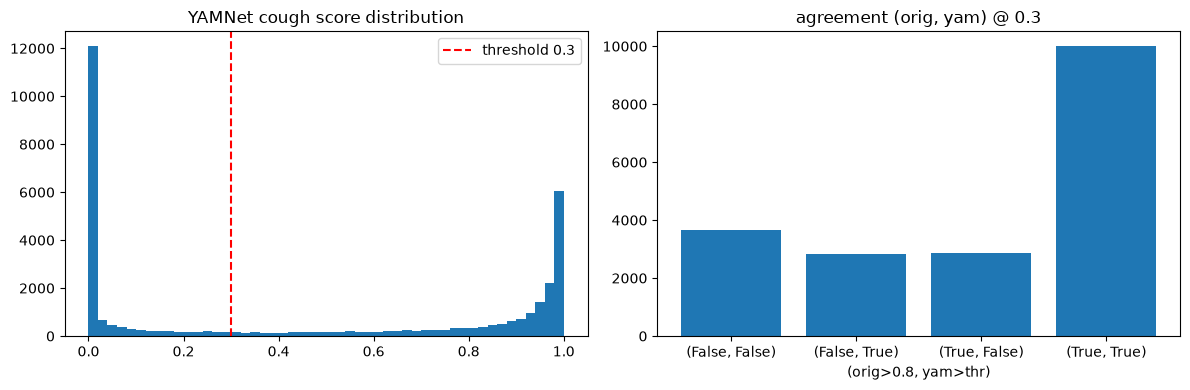

per-status counts (orig filter vs yamnet filter):
shape: (3, 2)
┌─────────────┬───────┐
│ status      ┆ count │
│ ---         ┆ ---   │
│ str         ┆ u32   │
╞═════════════╪═══════╡
│ COVID-19    ┆ 634   │
│ healthy     ┆ 9629  │
│ symptomatic ┆ 2622  │
└─────────────┴───────┘
shape: (3, 2)
┌─────────────┬───────┐
│ status      ┆ count │
│ ---         ┆ ---   │
│ str         ┆ u32   │
╞═════════════╪═══════╡
│ COVID-19    ┆ 648   │
│ healthy     ┆ 9583  │
│ symptomatic ┆ 2622  │
└─────────────┴───────┘


In [30]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['cough_detected_yamnet'].drop_nulls().to_numpy(), bins=50)
axes[0].axvline(THRESHOLD, color='r', ls='--', label=f'threshold {THRESHOLD}')
axes[0].set_title('YAMNet cough score distribution'); axes[0].legend()

b = base.with_columns(
    (pl.col('cough_detected') > 0.8).alias('orig'),
    (pl.col('cough_detected_yamnet') > THRESHOLD).alias('yam'),
).group_by(['orig', 'yam']).len().sort('orig', 'yam')
axes[1].bar([str(r) for r in b.select(['orig', 'yam']).rows()], b['len'])
axes[1].set_title(f'agreement (orig, yam) @ {THRESHOLD}'); axes[1].set_xlabel('(orig>0.8, yam>thr)')
plt.tight_layout(); plt.show()

print('per-status counts (orig filter vs yamnet filter):')
print(df_orig['status'].value_counts().sort('status'))
print(df_yam['status'].value_counts().sort('status'))

In [26]:
# spot-check disagreements: orig says no, yamnet says cough (and vice versa)
from IPython.display import Audio, display

dis = base.with_columns(
    (pl.col('cough_detected') > 0.8).alias('orig'),
    (pl.col('cough_detected_yamnet') > THRESHOLD).alias('yam'),
).filter(pl.col('orig') != pl.col('yam')).filter(pl.col('cough_detected_yamnet').is_not_null())
print(f'{len(dis)} disagreements; sample:')
for row in dis.head(4).iter_rows(named=True):
    print(f"orig={row['orig']} yam={row['yam']} score={row['cough_detected_yamnet']:.3f}  {row['wav_path']}")
    display(Audio(row['wav_path']))

5712 disagreements; sample:
orig=True yam=False score=0.032  data/public_dataset_v3_wav/0f0762c8-4b9a-4c1e-a6c3-230f9d53de47.wav


orig=False yam=True score=0.993  data/public_dataset_v3_wav/3a39cca7-5731-4274-ab98-998e2b89efb4.wav


orig=False yam=True score=0.793  data/public_dataset_v3_wav/8e54b4c9-34b3-4bdf-abd2-fb56cae779a7.wav


orig=True yam=False score=0.198  data/public_dataset_v3_wav/50d84a8d-3b91-425d-b6b6-618b44145a92.wav


In [59]:
# play audio of individual segments — passing and failing, for comparison
from IPython.display import Audio, display

def play_segments(wav_path: str, threshold: float = THRESHOLD):
    """Segment a wav, score each segment, and play all of them labelled pass/fail."""
    wave, sr = sf.read(wav_path, dtype='float32')
    if wave.ndim > 1:
        wave = wave.mean(axis=1)
    segs, _ = segment_cough_fast(wave, sr, cough_padding=0.1, min_cough_len=0.1)
    if not segs:
        print(f'{wav_path}: no cough-like segments')
        return
    for j, seg in enumerate(segs):
        frames = seg_to_frames(seg, sr)
        score = frame_cough_scores(frames.to(DEVICE)).max().item()
        mark = 'PASS' if score > threshold else 'FAIL'
        print(f'seg {j}: score {score:.3f} [{mark}]  {len(seg)/sr:.2f}s')
        display(Audio(seg, rate=sr))

# demo: one file yamnet passes, one it scores 0
play_segments(df.filter(pl.col('cough_detected_yamnet') > THRESHOLD)['wav_path'][901])
play_segments(df['wav_path'][11])
print(df.filter(pl.col('cough_detected_yamnet') > THRESHOLD, pl.col("cough_detected") > 0.8))
print(df["cough_detected_yamnet"].to_numpy()[:100])

seg 0: score 0.973 [PASS]  0.53s


seg 1: score 0.905 [PASS]  0.53s


seg 0: score 0.007 [FAIL]  0.38s


seg 1: score 0.000 [FAIL]  0.41s


seg 2: score 0.000 [FAIL]  0.38s


seg 3: score 0.003 [FAIL]  0.44s


shape: (14_037, 13)
┌───────────┬───────────┬──────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ datetime  ┆ cough_det ┆ latitude ┆ longitude ┆ … ┆ file_name ┆ audio_nam ┆ wav_path  ┆ cough_det │
│ ---       ┆ ected     ┆ ---      ┆ ---       ┆   ┆ ---       ┆ e         ┆ ---       ┆ ected_yam │
│ str       ┆ ---       ┆ f64      ┆ f64       ┆   ┆ str       ┆ ---       ┆ str       ┆ net       │
│           ┆ f64       ┆          ┆           ┆   ┆           ┆ str       ┆           ┆ ---       │
│           ┆           ┆          ┆           ┆   ┆           ┆           ┆           ┆ f64       │
╞═══════════╪═══════════╪══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 2020-11-1 ┆ 0.9886    ┆ 42.4     ┆ 3.2       ┆ … ┆ 48b283df- ┆ 48b283df- ┆ data/publ ┆ 0.99297   │
│ 8T20:30:5 ┆           ┆          ┆           ┆   ┆ 8bda-4766 ┆ 8bda-4766 ┆ ic_datase ┆           │
│ 4.833009+ ┆           ┆          ┆           ┆   ┆ -b02e-0ef ┆ -b02e-